# Inherent Structures: Langevin to Quench
This notebook runs the temperature experiment directly from Colab: equilibrate with full-batch Langevin dynamics, quench with full-batch gradient descent, and measure the loss and overlap at the inherent structure.

In [ ]:
# Colab setup: mount Google Drive and keep the repository/results persistent.
from pathlib import Path
from google.colab import drive

drive.mount("/content/drive")

DRIVE_ROOT = Path("/content/drive/MyDrive")
REPO_ROOT = DRIVE_ROOT / "Comparing_Dynamics"
EXPERIMENT_ROOT = DRIVE_ROOT / "STUDIA/PhD/ICML_2026_Hessian_Eigenvectors"
REPO_URL = "https://github.com/marjankowskam/Comparing_Dynamics.git"

%cd {REPO_ROOT}
%pip install -r requirements.txt
%pip install -e .

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Cloning into 'PINN_hessian'...
remote: Enumerating objects: 1165, done.
remote: Counting objects: 100% (143/143), done.
remote: Compressing objects: 100% (104/104), done.
remote: Total 1165 (delta 68), reused 110 (delta 39), pack-reused 1022 (from 1)
Receiving objects: 100% (1165/1165), 118.13 MiB | 34.65 MiB/s, done.
Resolving deltas: 100% (691/691), done.
[Errno 2] No such file or directory: '/content/drive/MyDrive/Comparing_Dynamics'
/content
ERROR: Could not open requirements file: [Errno 2] No such file or directory: 'requirements.txt'
Obtaining file:///content
ERROR: file:///content does not appear to be a Python project: neither 'setup.py' nor 'pyproject.toml' found.


In [ ]:
import sys
from pathlib import Path

sys.path.insert(0, str(REPO_ROOT))

import torch
import wandb

from comparing_dynamics.config import Config
from comparing_dynamics.models import get_model
from comparing_dynamics.train_utils import init_weights, set_random_seed
from comparing_dynamics.experiments.inherent_structures import (
    InherentStructureConfig,
    run_inherent_structure,
)

device = "cuda" if torch.cuda.is_available() else "cpu"
output_dir = EXPERIMENT_ROOT / "inherent-structures"

In [ ]:
cfg = Config(
    initial_seed=19,
    task_name="fashion_mnist",
    task_params={"batch_size": None, "data_dir": "data"},
    model_name="mnistMLP",
    model_params={
        "hidden_dim": [100, 100, 10],
        "activation_fn": "relu",
    },
)

equilibration_steps = 1000
quench_steps = 5000
langevin_lr = 1e-3
quench_lr = 1e-2
temperatures = [0.0, 0.01, 0.1, 1.0]

In [ ]:
results = []

for temperature in temperatures:
    cfg.initial_seed = 19
    wb_run = wandb.init(
        project="comparing-dynamics",
        name=f"fashion-mnist-T-{temperature:g}",
        config={
            "temperature": temperature,
            "equilibration_steps": equilibration_steps,
            "quench_steps": quench_steps,
            "langevin_lr": langevin_lr,
            "quench_lr": quench_lr,
            "device": device,
        },
    )
    try:
        experiment_cfg = InherentStructureConfig(
            temperature=temperature,
            equilibration_steps=equilibration_steps,
            quench_steps=quench_steps,
            langevin_lr=langevin_lr,
            quench_lr=quench_lr,
            seed=cfg.initial_seed,
        )
        result = run_inherent_structure(
            cfg,
            experiment_cfg,
            device=device,
            save_dir=output_dir,
            run_name=wb_run.name,
        )
        wandb.log({
            "inherent_loss": result["final_loss"],
            "inherent_gradient_norm": result["final_gradient_norm"],
            "overlap_q": result["overlap_q"],
            "initial_to_inherent_overlap": result["initial_to_inherent_overlap"],
        })
        results.append(result)
    finally:
        wandb.finish()

In [ ]:
import pandas as pd

summary = pd.DataFrame([
    {
        "temperature": result["temperature"],
        "inherent_loss": result["final_loss"],
        "gradient_norm": result["final_gradient_norm"],
        "overlap_q": result["overlap_q"],
        "initial_to_inherent_overlap": result["initial_to_inherent_overlap"],
    }
    for result in results
])
summary

In [ ]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].plot(summary["temperature"], summary["inherent_loss"], marker="o")
axes[0].set(xlabel="Temperature T", ylabel="Inherent-structure loss")
axes[1].plot(summary["temperature"], summary["overlap_q"], marker="o")
axes[1].set(xlabel="Temperature T", ylabel="q(T)")
fig.tight_layout()

# SGD to Quench


In [1]:
import sys
!{sys.executable} -m pip install -e "C:/Users/mmarc/Documents/code/Comparing_Dynamics"

Obtaining file:///C:/Users/mmarc/Documents/code/Comparing_Dynamics
  Installing build dependencies: started
  Installing build dependencies: finished with status 'done'
  Checking if build backend supports build_editable: started
  Checking if build backend supports build_editable: finished with status 'done'
  Getting requirements to build editable: started
  Getting requirements to build editable: finished with status 'done'
  Preparing editable metadata (pyproject.toml): started
  Preparing editable metadata (pyproject.toml): finished with status 'done'
  Building editable for comparing-dynamics (pyproject.toml): started
  Building editable for comparing-dynamics (pyproject.toml): finished with status 'done'
  Created wheel for comparing-dynamics: filename=comparing_dynamics-0.1.0-0.editable-py3-none-any.whl size=2903 sha256=320f86dea4b57f6d82928ff6be1dba7224a982d896f33287b7d37fc24dc45d5f
  Stored in directory: C:\Users\mmarc\AppData\Local\Temp\pip-ephem-wheel-cache-wkh1rczc\wheels\

In [59]:
import sys
from pathlib import Path

REPO_ROOT = Path(r"C:/Users/mmarc/Documents/code/Comparing_Dynamics")
sys.path.insert(0, str(REPO_ROOT))

import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
from comparing_dynamics.config import Config
import gc

In [20]:
df_metrics

""


In [26]:
# Load the W&B export from the repository data directory.
base_path = EXPERIMENT_ROOT
metrics_path = REPO_ROOT / "data" / "wandb_export_ICML_runs.csv"
df = pd.read_csv(metrics_path)

# Normalize the W&B export so run metadata and metrics use stable column names.
df = df.rename(columns={
    "Name": "run_name",
})
required_columns = {"run_name", "opt_name", "task_name", "loss", "accuracy", "grad_norm"}
missing_columns = required_columns - set(df.columns)
if missing_columns:
    raise KeyError(f"Missing columns in W&B export: {sorted(missing_columns)}")

filtered = df[
    df["opt_name"].astype(str).str.lower().eq("sgd")
    & df["task_name"].astype(str).str.lower().eq("mnist")
].drop_duplicates(subset=["run_name"])
metrics_by_run = df.set_index("run_name")
df_metrics = df  # Compatibility with the exploratory cells below.
filtered[["run_name", "opt_name", "task_name"]]

In [36]:
run_names =filtered["run_name"].values

In [37]:

"there are " + str(len(filtered)) + " available runs"

'there are 35 available runs'

In [ ]:
T = {}
for run_name in filtered["run_name"]:
    run_cfg = Config.load_from_file(run_name, str(EXPERIMENT_ROOT) + "/")
    batch_size = run_cfg.task_params.get("batch_size")
    if batch_size is None or batch_size == 0:
        raise ValueError(f"Invalid batch size for {run_name}: {batch_size}")
    T[run_name] = run_cfg.opt_params["lr"] / batch_size

T

In [38]:
T.values()

dict_values([7.8125e-05, 7.8125e-05, 7.8125e-05, 7.8125e-05, 7.8125e-05, 0.00078125, 7.8125e-05, 0.000234375, 2.34375e-05, 7.8125e-06, 7.8125e-07, 0.0003125, 0.00078125, 0.0003125, 7.8125e-05, 0.0003125, 0.000234375, 2.34375e-05, 7.8125e-06, 0.00015625, 7.8125e-07, 0.00015625, 7.8125e-05, 0.00015625, 0.00078125, 0.000234375, 2.34375e-05, 7.8125e-06, 7.8125e-07, 9.765625e-06, 9.765625e-06, 9.765625e-06, 1.6666666666666668e-07, 1.6666666666666668e-07, 1.6666666666666668e-07])

In [17]:
r.keys()

dict_keys(['all_timesteps', 'tw_list', 'indexes', 'weight_displacement', 'eigv', 'eig', 'model param change', 'eigv1_weight_correlation', 'eigv1_displacement', 'eigv1_alignment', 'eigv1_dot_grad_vec', 'eigv1_dot_update', 'eigv2_weight_correlation', 'eigv2_displacement', 'eigv2_alignment', 'eigv2_dot_grad_vec', 'eigv2_dot_update', 'eigv3_weight_correlation', 'eigv3_displacement', 'eigv3_alignment', 'eigv3_dot_grad_vec', 'eigv3_dot_update'])

In [44]:
# Optional: load leading Hessian eigenvalues when those files are available.
leading_eigenvalue = {}
for run_name in filtered["run_name"]:
    result_path = EXPERIMENT_ROOT / f"hResults_{run_name}.pt"
    if not result_path.exists():
        continue
    hessian_result = torch.load(result_path, weights_only=False, map_location="cpu")
    leading_eigenvalue[run_name] = hessian_result["eig"][-1][0]
    del hessian_result
    gc.collect()

if leading_eigenvalue:
    print(
        np.max(list(leading_eigenvalue.values())),
        np.min(list(leading_eigenvalue.values())),
    )
else:
    print("No Hessian files found; using the configured quench learning rate.")

dict_values([np.float32(2.5304577), np.float32(4.310328), np.float32(11.130252), np.float32(2.9055717), np.float32(6.9053326), np.float32(0.042966492), np.float32(2.5304575), np.float32(0.4174288), np.float32(16.502409), np.float32(26.310099), np.float32(35.42198), np.float32(0.29738116), np.float32(0.04480193), np.float32(0.24521708), np.float32(2.1851933), np.float32(0.26969013), np.float32(0.39251587), np.float32(13.036277), np.float32(18.3259), np.float32(0.93211704), np.float32(23.316223), np.float32(0.7351624), np.float32(2.8558304), np.float32(0.8001576), np.float32(0.048752375), np.float32(0.45146367), np.float32(16.532629), np.float32(21.84567), np.float32(28.84857), np.float32(21.325304), np.float32(17.67287), np.float32(25.605265), np.float32(22.347294), np.float32(12.822512), np.float32(30.274094)]) dict_values([np.float32(2.5304577), np.float32(4.310328), np.float32(11.130252), np.float32(2.9055717), np.float32(6.9053326), np.float32(0.042966492), np.float32(2.5304575), np

In [46]:
print(np.max(np.array(list(leading_eigenvalue.values()))), np.min(np.array(list(leading_eigenvalue.values()))))


35.42198 0.042966492


In [47]:
# So we decide to use learning rate
0.5/np.max(np.array(list(leading_eigenvalue.values())))
# i.e. 0.014

np.float32(0.014115529)

In [19]:
df_metrics

""


In [29]:
metric = df_metrics[["run_name", "loss", "grad_norm", "accuracy"]].set_index("run_name").to_dict(orient="index")

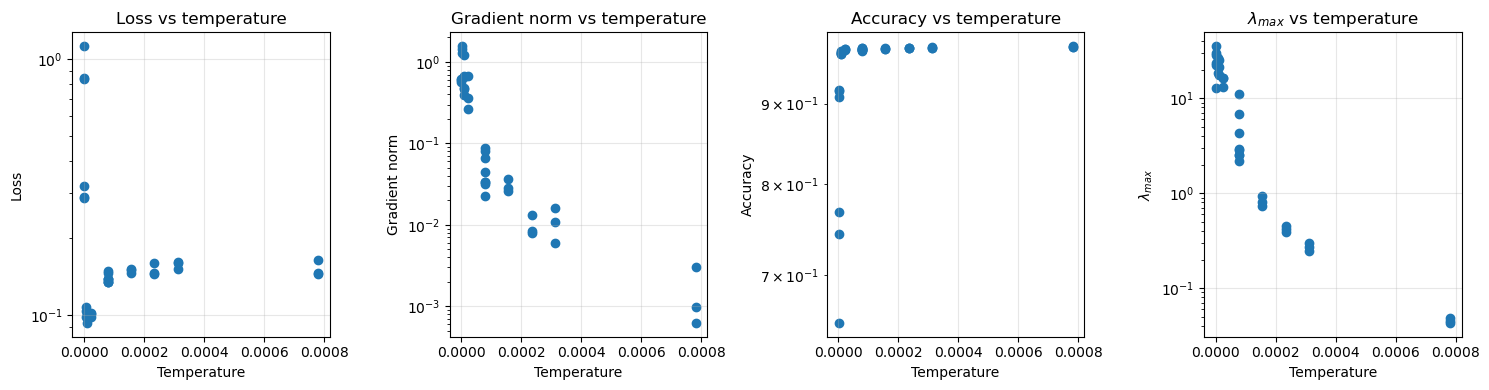

In [57]:
import matplotlib.pyplot as plt
plt.rcParams["text.usetex"] = False

metric = metrics_by_run[["loss", "grad_norm", "accuracy"]].to_dict(orient="index")
plot_runs = [
    run_name
    for run_name in filtered["run_name"]
    if run_name in metric
]
metrics = {
    "Loss": {run_name: metric[run_name]["loss"] for run_name in plot_runs},
    "Gradient norm": {run_name: metric[run_name]["grad_norm"] for run_name in plot_runs},
    "Accuracy": {run_name: metric[run_name]["accuracy"] for run_name in plot_runs},
}
if leading_eigenvalue:
    hessian_runs = [run_name for run_name in plot_runs if run_name in leading_eigenvalue]
    if hessian_runs:
        metrics[r"$\lambda_{max}$"] = {
            run_name: leading_eigenvalue[run_name]
            for run_name in hessian_runs
        }

fig, axes = plt.subplots(1, len(metrics), figsize=(5 * len(metrics), 4), squeeze=False)
for ax, (metric_name, metric_dict) in zip(axes[0], metrics.items()):
    runs = list(metric_dict)
    ax.scatter([T[run] for run in runs], list(metric_dict.values()))
    ax.set_xlabel("Effective SGD temperature (lr / batch size)")
    ax.set_ylabel(metric_name)
    ax.set_title(f"{metric_name} vs effective temperature")
    ax.grid(alpha=0.3)
    ax.set_yscale("log")

plt.tight_layout()
plt.show()

In [58]:
quench_steps = 50000
quench_lr = 0.014
quench_tolerance = 1e-6
sgd_to_quench_dir = EXPERIMENT_ROOT / "inherent-structures" / "sgd-to-quench"
sgd_to_quench_dir.mkdir(parents=True, exist_ok=True)
sgd_to_quench_results = []

for run_name in filtered["run_name"]:
    try:
        run_cfg = Config.load_from_file(run_name, str(EXPERIMENT_ROOT) + "/")
        checkpoint_path = EXPERIMENT_ROOT / f"Model_{run_name}.pt"
        checkpoint = torch.load(
            checkpoint_path,
            map_location=device,
            weights_only=False,
        )
    except FileNotFoundError:
        print(f"Missing config or checkpoint: {run_name}")
        continue

    set_random_seed(run_cfg.initial_seed)
    model = get_model(run_cfg.model_name, run_cfg.model_params)
    model.apply(init_weights)
    initial_parameters = torch.nn.utils.parameters_to_vector(
        model.parameters()
    ).detach().clone()
    model.load_state_dict(checkpoint["model_state_dict"])

    experiment_cfg = InherentStructureConfig(
        temperature=0.0,
        equilibration_steps=0,
        quench_steps=quench_steps,
        langevin_lr=0.0,
        quench_lr=quench_lr,
        quench_tolerance=quench_tolerance,
        seed=run_cfg.initial_seed,
    )
    result = run_inherent_structure(
        run_cfg,
        experiment_cfg,
        device=device,
        model=model,
        initial_parameters=initial_parameters,
        save_dir=sgd_to_quench_dir,
        run_name=run_name,
    )
    result["run_name"] = run_name
    sgd_to_quench_results.append(result)

sgd_to_quench_summary = pd.DataFrame([
    {
        "run_name": result["run_name"],
        "effective_temperature": T[result["run_name"]],
        "sgd_loss": metrics_by_run.loc[result["run_name"], "loss"],
        "sgd_accuracy": metrics_by_run.loc[result["run_name"], "accuracy"],
        "sgd_grad_norm": metrics_by_run.loc[result["run_name"], "grad_norm"],
        "inherent_loss": result["final_loss"],
        "inherent_gradient_norm": result["final_gradient_norm"],
        "sgd_to_inherent_overlap": result["overlap_q"],
        "initial_to_inherent_overlap": result["initial_to_inherent_overlap"],
        "checkpoint": result["saved_files"]["inherent_checkpoint"],
    }
    for result in sgd_to_quench_results
])
summary_path = sgd_to_quench_dir / "sgd_to_quench_summary.csv"
sgd_to_quench_summary.to_csv(summary_path, index=False)
print(f"Saved {len(sgd_to_quench_summary)} runs to {sgd_to_quench_dir}")
sgd_to_quench_summary

NameError: name 'EXPERIMENT_ROOT' is not defined